In [1]:
import pandas as pd

In [2]:
pjme_data = pd.read_csv("../data/PJME_hourly.csv")

In [3]:
pjme_data.shape

(145366, 2)

In [4]:
pjme_data.size

290732

In [5]:
pjme_data.isnull().sum()

Datetime    0
PJME_MW     0
dtype: int64

In [6]:
pjme_data.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [7]:
pjme_data.dtypes

Datetime     object
PJME_MW     float64
dtype: object

In [8]:
pjme_data["Datetime"] = pd.to_datetime(pjme_data["Datetime"])

In [9]:
pjme_data = pjme_data.set_index('Datetime')

In [10]:
pjme_data = pjme_data.sort_index()

In [11]:
pjme_data.head()

,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [12]:
# creating time components
pjme_data["hour"] = pjme_data.index.hour
pjme_data["day_of_week"] = pjme_data.index.dayofweek
pjme_data["quarter"] = pjme_data.index.quarter
pjme_data["month"] = pjme_data.index.month
pjme_data["year"] = pjme_data.index.year
pjme_data["day_of_year"] = pjme_data.index.dayofyear

In [13]:
# create lag features 

pjme_data["24_lag"] = pjme_data["PJME_MW"].shift(24)
pjme_data["1week_lag"] = pjme_data["PJME_MW"].shift(168)

# remove empty rows

pjme_data = pjme_data.dropna()



In [14]:
pjme_data.head()

,PJME_MW,hour,day_of_week,quarter,month,year,day_of_year,24_lag,1week_lag
Datetime,,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,1,2002,8,26862.0,30393.0
2002-01-08 02:00:00,28670.0,2,1,1,1,2002,8,25976.0,29265.0
2002-01-08 03:00:00,28375.0,3,1,1,1,2002,8,25641.0,28357.0
2002-01-08 04:00:00,28542.0,4,1,1,1,2002,8,25666.0,27899.0
2002-01-08 05:00:00,29261.0,5,1,1,1,2002,8,26328.0,28057.0


In [15]:
import numpy as np

In [16]:
# converting stright line hours and months into cyclic

pjme_data["hour_sin"] = np.sin((2*np.pi * pjme_data["hour"])/24)
pjme_data["hour_cos"] = np.cos((2*np.pi * pjme_data["hour"])/24)

pjme_data["month_sin"] = np.sin((2*np.pi * pjme_data["hour"])/12)
pjme_data["month_cos"] = np.cos((2*np.pi * pjme_data["hour"])/12)

In [17]:
pjme_data.head()

,PJME_MW,hour,day_of_week,quarter,month,year,day_of_year,24_lag,1week_lag,hour_sin,hour_cos,month_sin,month_cos
Datetime,,,,,,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,1,2002,8,26862.0,30393.0,0.258819,0.965926,0.500000,8.660254e-01
2002-01-08 02:00:00,28670.0,2,1,1,1,2002,8,25976.0,29265.0,0.500000,0.866025,0.866025,5.000000e-01
2002-01-08 03:00:00,28375.0,3,1,1,1,2002,8,25641.0,28357.0,0.707107,0.707107,1.000000,6.123234e-17
2002-01-08 04:00:00,28542.0,4,1,1,1,2002,8,25666.0,27899.0,0.866025,0.500000,0.866025,-5.000000e-01
2002-01-08 05:00:00,29261.0,5,1,1,1,2002,8,26328.0,28057.0,0.965926,0.258819,0.500000,-8.660254e-01


In [27]:
pjme_data["year"].unique()

array([2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012,
       2013, 2014, 2015, 2016, 2017, 2018], dtype=int32)

In [37]:
target_date = '2015-01-01'
pjme_data_train = pjme_data[ pjme_data.index < target_date]
pjme_data_test = pjme_data[ pjme_data.index >= target_date]

In [39]:
pjme_data_train.size

1478854

In [40]:
pjme_data_test.size

408720

In [41]:
X_train = pjme_data_train.drop(columns = ["PJME_MW"])
y_train = pjme_data_train["PJME_MW"]

X_test = pjme_data_test.drop(columns = ["PJME_MW"])
y_test = pjme_data_test["PJME_MW"]

In [45]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)



In [60]:
y_train_scaler = scaler.fit_transform(y_train.values.reshape(-1,1))
y_test_scaler = scaler.transform(y_test.values.reshape(-1,1))

In [61]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim

In [69]:
# converting the data into tensors

X_train_tensors = torch.tensor(X_train_scaler, dtype = torch.float32)
y_train_tensors = torch.tensor(y_train_scaler, dtype = torch.float32)

X_test_tensors = torch.tensor(X_test_scaler, dtype = torch.float32)
y_test_tensors = torch.tensor(y_test_scaler, dtype = torch.float32)



In [70]:
# tensordataset

train_dataset = TensorDataset(X_train_tensors, y_train_tensors)
test_dataset = TensorDataset(X_test_tensors, y_test_tensors)

In [71]:
train_loader = DataLoader(train_dataset, batch_size = 48, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size = 48, shuffle = True)

In [72]:
# ANN Model
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model = nn.Sequential(

            # 1st hidden layer
            nn.Linear(X_train.shape[1],128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            # 2nd hidden layer
            nn.Linear(128,64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            # output layer
            nn.Linear(64,1)
            
        )
    def forward(self,x):
        return self.model(x)
        

In [73]:
#ANN
Model = ANN()
criterian = nn.MSELoss()
optimizer = optim.Adam(Model.parameters(), lr = 0.001)

In [74]:
# Training model
train_loss = []
val_loss = []
best_val_loss = float("inf")
epochs = 50

for epoch in range(epochs):
    Model.train()
    running_loss = 0.0

    for xb,yb in train_loader:

        optimizer.zero_grad()
        outputs = Model(xb)
        loss = criterian(outputs,yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        
    epoch_train_loss = running_loss /len(train_loader)
    train_loss.append(epoch_train_loss)

    #validation

    Model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for xb, yb in test_loader:
            outputs = Model(xb)
            loss = criterian(outputs,yb)
            running_loss += loss.item()
    epoch_val_loss =  running_loss /len(test_loader)
    val_loss.append(epoch_val_loss)

    print(f"epoch : {epoch+1}, epochtrainloss : {epoch_train_loss}, epochtestloss :{epoch_val_loss} ")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(Model.state_dict(),"best_model.pt")
        

        
    


epoch : 1, epochtrainloss : 0.18368681175830748, epochtestloss :0.16124779256131813 
epoch : 2, epochtrainloss : 0.16801755867961338, epochtestloss :0.15416590281342732 
epoch : 3, epochtrainloss : 0.16459657384813586, epochtestloss :0.15377756001726361 
epoch : 4, epochtrainloss : 0.16145071102785663, epochtestloss :0.15089884377617874 
epoch : 5, epochtrainloss : 0.15970728929284253, epochtestloss :0.15344472172037335 
epoch : 6, epochtrainloss : 0.15797670704277256, epochtestloss :0.15365399607947763 
epoch : 7, epochtrainloss : 0.15605765268646715, epochtestloss :0.1530940722816318 
epoch : 8, epochtrainloss : 0.15582535876597783, epochtestloss :0.1509828420654508 
epoch : 9, epochtrainloss : 0.15441425263975994, epochtestloss :0.1564243021925897 
epoch : 10, epochtrainloss : 0.15415772072153505, epochtestloss :0.14818124994635581 
epoch : 11, epochtrainloss : 0.15327062542365574, epochtestloss :0.14984901913136017 
epoch : 12, epochtrainloss : 0.15281363861784653, epochtestloss :0

In [76]:
 Model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [80]:
#Evaluate our model
Model.eval()
with torch.no_grad():
    train_preds = Model(X_train_tensors)
    test_preds = Model(X_test_tensors)

    train_mse_loss = criterian(train_preds,y_train_tensors)
    test_mse_loss = criterian(test_preds,y_test_tensors)

print("Training MSE" ,train_mse_loss.item())
print("Testing MSE" ,test_mse_loss.item())

Training MSE 0.11216024309396744
Testing MSE 0.14546017348766327


In [86]:


# 1. Unscale predictions and actual target values back to original Megawatts (MW)
predictions_mw = scaler.inverse_transform(test_preds.numpy())
y_test_mw = scaler.inverse_transform(y_test_tensors.numpy())

# 2. Create the comparison DataFrame using your original test datetime index
results_df = pd.DataFrame({
    'Actual Load (MW)': y_test_mw.flatten(),
    'Predicted Load (MW)': predictions_mw.flatten()
}, index=pjme_data_test.index)

# 3. Add an Absolute Error column
results_df['Difference (MW)'] = (results_df['Actual Load (MW)'] - results_df['Predicted Load (MW)']).abs()

# Display the first 10 rows
results_df.head(10)

,Actual Load (MW),Predicted Load (MW),Difference (MW)
Datetime,,,
2015-01-01 00:00:00,32802.0,31811.451172,990.548828
2015-01-01 01:00:00,31647.0,30003.902344,1643.097656
2015-01-01 02:00:00,30755.0,29125.580078,1629.419922
2015-01-01 03:00:00,30189.0,28676.939453,1512.060547
2015-01-01 04:00:00,29890.0,28618.126953,1271.873047
2015-01-01 05:00:00,30075.0,28966.197266,1108.802734
2015-01-01 06:00:00,30726.0,30280.111328,445.888672
2015-01-01 07:00:00,31628.0,32457.511719,829.511719
2015-01-01 08:00:00,31815.0,33867.996094,2052.996094


In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test_mw, predictions_mw)
rmse = np.sqrt(mean_squared_error(y_test_mw, predictions_mw))
r2 = r2_score(y_test_mw, predictions_mw)

print(f"--- Model Performance on Unseen Test Data ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} MW")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} MW")
print(f"R² Score: {r2:.4f}")

--- Model Performance on Unseen Test Data ---
Mean Absolute Error (MAE): 1811.37 MW
Root Mean Squared Error (RMSE): 2462.02 MW
R² Score: 0.8543


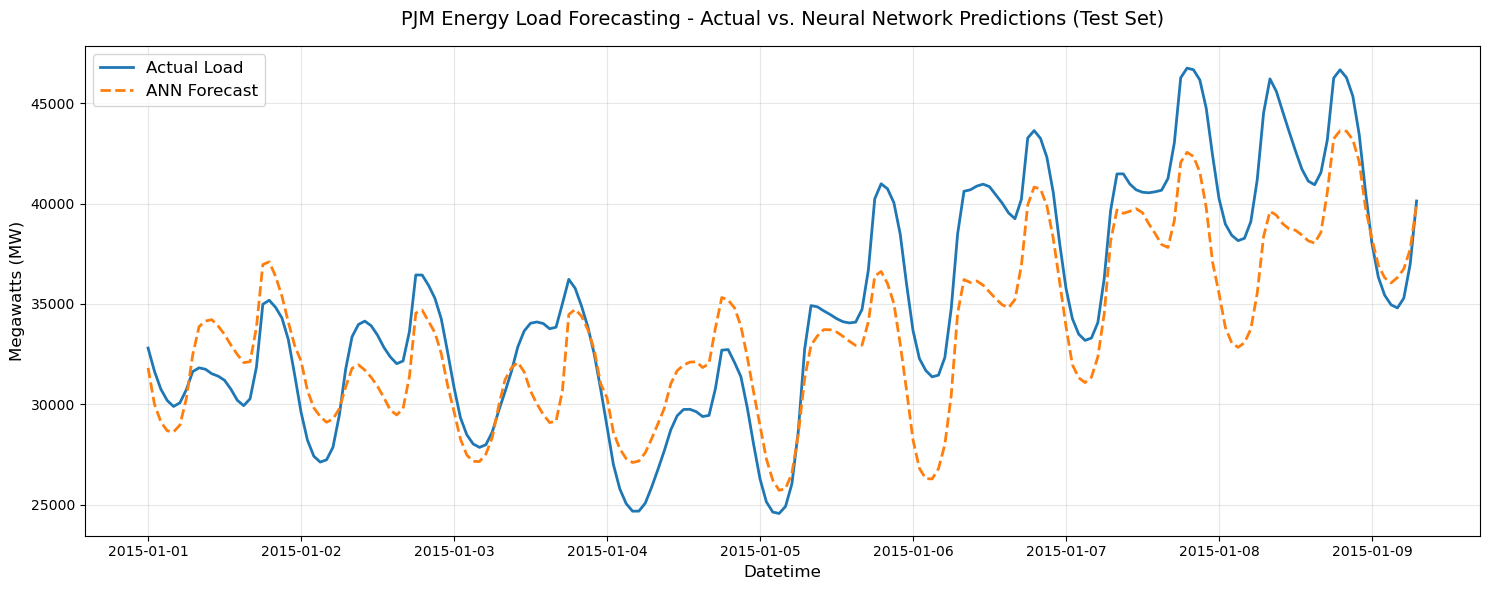

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
# Plot first 200 hours (~8 days) to see the daily curve match clearly
plt.plot(results_df.index[:200], results_df['Actual Load (MW)'][:200], label='Actual Load', color='#1f77b4', linewidth=2)
plt.plot(results_df.index[:200], results_df['Predicted Load (MW)'][:200], label='ANN Forecast', color='#ff7f0e', linestyle='--', linewidth=2)

plt.title('PJM Energy Load Forecasting - Actual vs. Neural Network Predictions (Test Set)', fontsize=14, pad=15)
plt.xlabel('Datetime', fontsize=12)
plt.ylabel('Megawatts (MW)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../actual_vs_predicted.png', dpi=300)
plt.show()